### TDSP · Fase 2: Comprensión de los datos

Exploración del grupo de entrenamiento y limpieza de ambos grupos.

- **Entradas:** `Sample_Data/Processed/train.csv`, `Sample_Data/Processed/test.csv`
- **Salidas:**
  - `Sample_Data/For_Modeling/train_clean.csv`, `Sample_Data/For_Modeling/test_clean.csv`: datos limpios
  - `Sample_Data/Processed/data_quality.csv`: resumen de calidad por variable
  - `Docs/Data_Report/figures/`: figuras de la exploración
- **Variable objetivo:** `Revenue`

#### Librerías

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

#### Rutas

Relativas a la carpeta del notebook.

In [2]:
PROCESSED_DIR = Path("../../Sample_Data/Processed")
FOR_MODELING_DIR = Path("../../Sample_Data/For_Modeling")
FIGURES_DIR = Path("../../Docs/Data_Report/figures")
FOR_MODELING_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#### Estilo de las figuras

In [3]:
COLORS = {0: "#2a78d6", 1: "#eb6834"}
LABELS = {0: "No compra", 1: "Compra"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

#### Carga de datos

La exploración usa solo el grupo de entrenamiento. El grupo de prueba se carga únicamente para aplicarle la misma limpieza al final.

In [4]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

TARGET = "Revenue"
COUNTS = ["Administrative", "Informational", "ProductRelated"]
DURATIONS = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]
RATES = ["BounceRates", "ExitRates", "PageValues"]
NUMERIC = COUNTS + DURATIONS + RATES
CODES = ["OperatingSystems", "Browser", "Region", "TrafficType"]
CATEGORICAL = ["Month", "VisitorType", "Weekend", "SpecialDay"] + CODES

y = train[TARGET].astype(int)
print(f"Entrenamiento: {len(train):,} sesiones | Compras: {y.sum():,} ({y.mean():.1%})")

Entrenamiento: 9,864 sesiones | Compras: 1,526 (15.5%)


#### Estadística descriptiva de las variables numéricas

In [5]:
train[NUMERIC].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,9864.0,2.31,3.31,0.0,0.00,1.00,4.00,27.00
Informational,9864.0,0.49,1.26,0.0,0.00,0.00,0.00,24.00
ProductRelated,9864.0,31.65,44.37,0.0,7.00,18.00,37.00,705.00
Administrative_Duration,9864.0,80.59,177.13,0.0,0.00,8.00,92.00,2720.50
Informational_Duration,9864.0,32.70,136.32,0.0,0.00,0.00,0.00,2256.92
ProductRelated_Duration,9864.0,1187.13,1847.72,0.0,184.00,592.92,1464.83,43171.23
BounceRates,9864.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,9864.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,9864.0,5.80,18.08,0.0,0.00,0.00,0.00,360.95


#### Asimetría

Valores mayores que 1 indican una cola larga hacia la derecha: la mayoría de las sesiones tiene valores bajos y unas pocas, valores muy altos.

In [6]:
train[NUMERIC].skew().round(2).to_frame("asimetria")

,asimetria
Administrative,1.95
Informational,4.20
ProductRelated,4.38
Administrative_Duration,5.51
Informational_Duration,7.82
ProductRelated_Duration,5.32
BounceRates,2.99
ExitRates,2.16
PageValues,6.14


#### Variables numéricas por clase

In [7]:
by_class = train.groupby(y)[NUMERIC].agg(["median", "mean"]).T.round(2)
by_class.columns = [LABELS[c] for c in by_class.columns]
by_class

No compra   Compra
Administrative          median       0.00     2.00
                        mean         2.12     3.39
Informational           median       0.00     0.00
                        mean         0.44     0.76
ProductRelated          median      16.00    28.00
                        mean        28.75    47.55
Administrative_Duration median       0.00    51.60
                        mean        73.54   119.11
Informational_Duration  median       0.00     0.00
                        mean        28.56    55.33
ProductRelated_Duration median     501.58  1081.81
                        mean      1067.61  1840.13
BounceRates             median       0.00     0.00
                        mean         0.02     0.01
ExitRates               median       0.03     0.02
                        mean         0.05     0.02
PageValues              median       0.00    16.52
                        mean         1.97    26.74

#### Distribución de las variables numéricas por clase

Eje horizontal en escala `log(1 + x)` por la asimetría. Cada curva está normalizada para comparar formas, no cantidades.

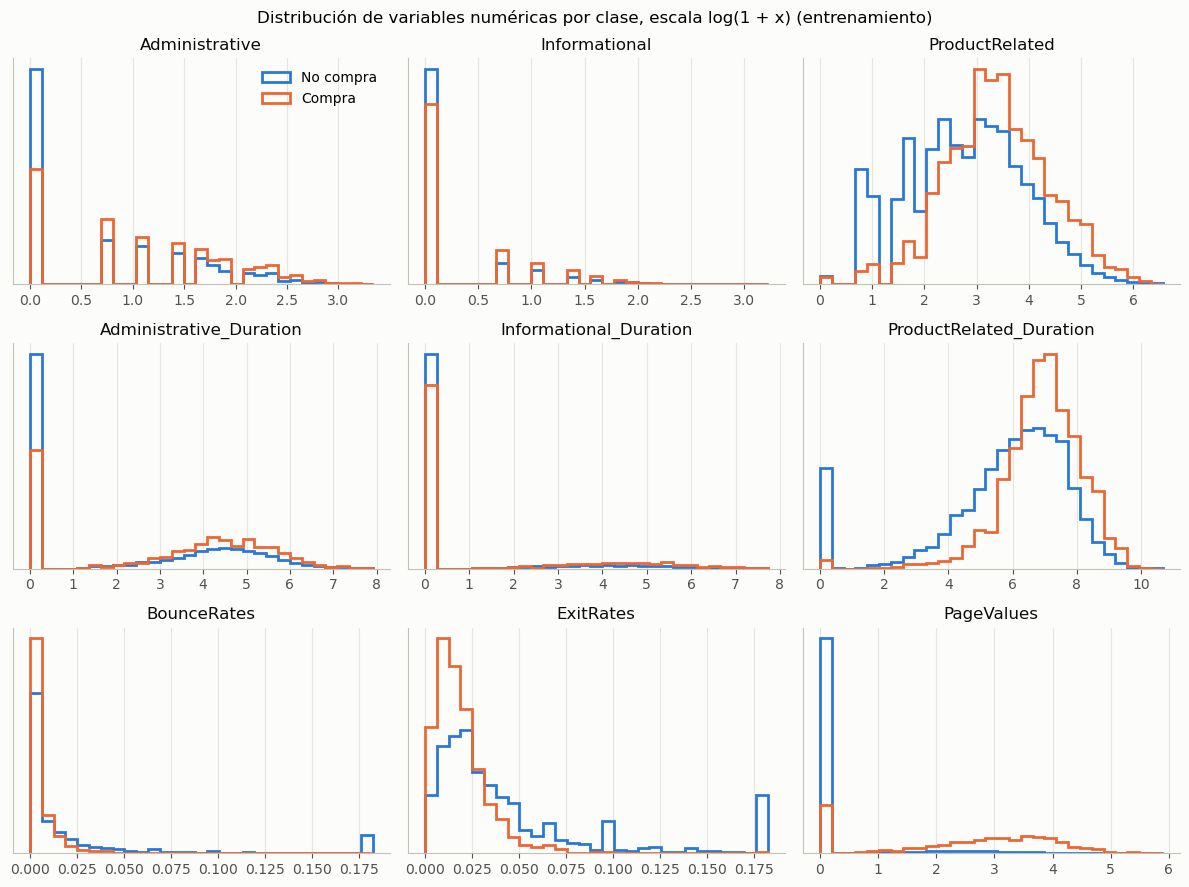

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))

for ax, col in zip(axes.flat, NUMERIC):
    values = np.log1p(train[col])
    bins = np.linspace(values.min(), values.max(), 30)
    for c in (0, 1):
        ax.hist(values[y == c], bins=bins, density=True, histtype="step",
                linewidth=2, color=COLORS[c], label=LABELS[c])
    ax.set_title(col)
    ax.set_yticks([])

axes[0, 0].legend()
fig.suptitle("Distribución de variables numéricas por clase, escala log(1 + x) (entrenamiento)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "numeric_distributions.png")
plt.show()

#### `PageValues` y la compra

In [9]:
has_pv = train["PageValues"] > 0

pd.DataFrame({
    "sesiones": has_pv.value_counts(),
    "tasa_de_compra": y.groupby(has_pv).mean().round(3),
}).rename(index={True: "PageValues > 0", False: "PageValues = 0"})

,sesiones,tasa_de_compra
PageValues,,
PageValues = 0,7681,0.039
PageValues > 0,2183,0.562


#### Tasa de compra por variable categórica

La línea discontinua marca la tasa de compra general del grupo de entrenamiento.

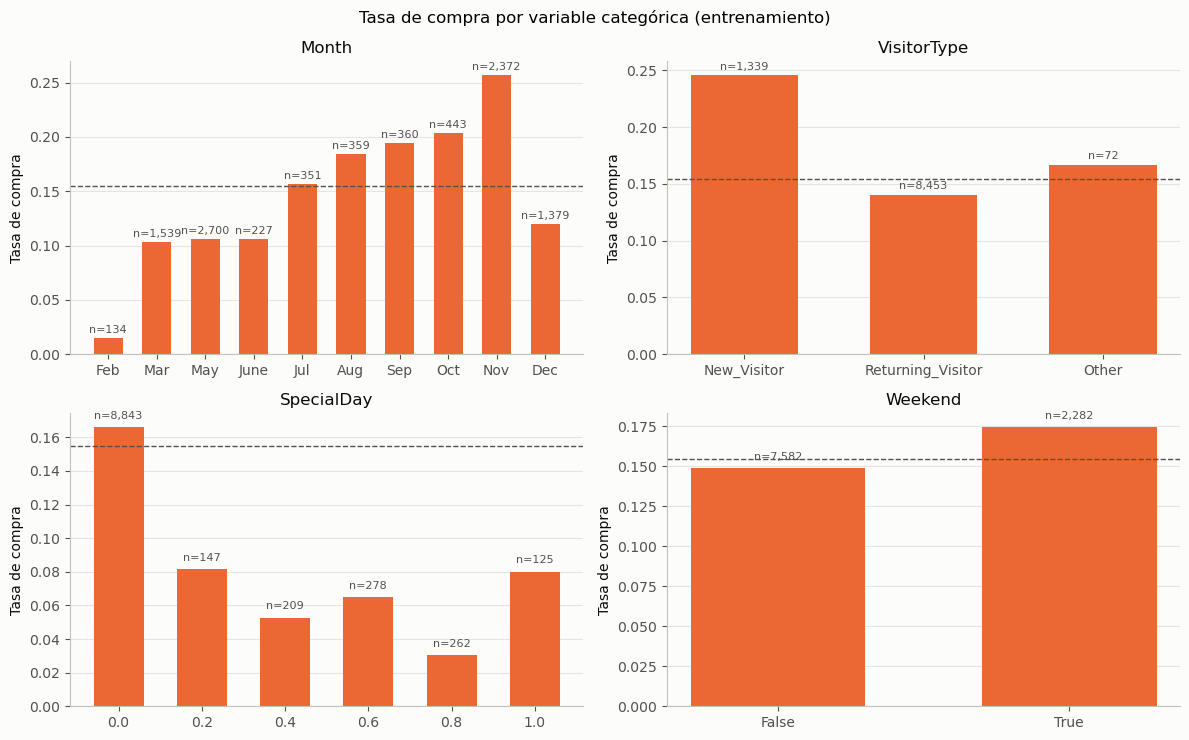

In [10]:
MONTH_ORDER = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
overall = y.mean()

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
panels = [
    ("Month", MONTH_ORDER),
    ("VisitorType", ["New_Visitor", "Returning_Visitor", "Other"]),
    ("SpecialDay", sorted(train["SpecialDay"].unique())),
    ("Weekend", [False, True]),
]

for ax, (col, order) in zip(axes.flat, panels):
    rate = y.groupby(train[col]).mean().reindex(order)
    count = train[col].value_counts().reindex(order)
    ax.bar([str(v) for v in order], rate.values, color=COLORS[1], width=0.6)
    ax.axhline(overall, color="#52514e", linestyle="--", linewidth=1)
    for i, (r, n) in enumerate(zip(rate.values, count.values)):
        ax.text(i, r + 0.005, f"n={n:,}", ha="center", fontsize=8, color="#52514e")
    ax.set_title(col)
    ax.set_ylabel("Tasa de compra")
    ax.grid(axis="x", visible=False)

fig.suptitle("Tasa de compra por variable categórica (entrenamiento)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "purchase_rate_by_category.png")
plt.show()

#### Categorías poco frecuentes en variables codificadas

Códigos con menos de 30 sesiones en entrenamiento.

In [11]:
MIN_COUNT = 30

rare = {
    col: train[col].value_counts()[lambda s: s < MIN_COUNT].to_dict()
    for col in CODES
}
for col, codes in rare.items():
    print(f"{col}: {codes if codes else 'ninguno'}")

OperatingSystems: {6: 13, 5: 6, 7: 4}
Browser: {12: 7, 11: 6, 9: 1}
Region: ninguno
TrafficType: {7: 29, 19: 15, 14: 13, 18: 9, 16: 2, 12: 1, 17: 1}


#### Correlación entre variables numéricas

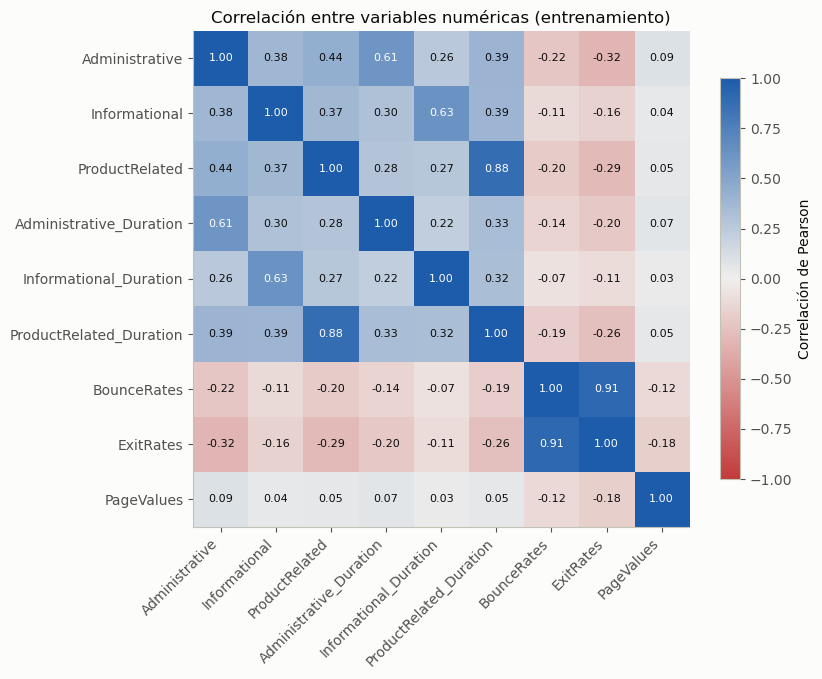

In [12]:
cmap = LinearSegmentedColormap.from_list("div", ["#c23b3b", "#f0efec", "#1c5cab"])
corr = train[NUMERIC].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=45, ha="right")
ax.set_yticks(range(len(NUMERIC)), NUMERIC)
ax.grid(False)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="#ffffff" if abs(v) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlación de Pearson")
ax.set_title("Correlación entre variables numéricas (entrenamiento)")
fig.savefig(FIGURES_DIR / "correlation.png")
plt.show()

#### Pares con correlación alta

Pares con correlación absoluta mayor que 0.7.

In [13]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.7].round(3).to_frame("correlacion")

,,correlacion
ProductRelated,ProductRelated_Duration,0.881
BounceRates,ExitRates,0.910


#### Filas repetidas en entrenamiento

In [14]:
dup = train.drop(columns="row_id").duplicated(keep=False)

print(f"Filas involucradas: {dup.sum()} | Con compra: {y[dup].sum()}")
print(f"Páginas de producto: {sorted(train.loc[dup, 'ProductRelated'].unique().tolist())}")
print(f"Duración total máxima: {train.loc[dup, DURATIONS].sum(axis=1).max()}")

Filas involucradas: 135 | Con compra: 0
Páginas de producto: [1, 2]
Duración total máxima: 0.0


#### Resumen de calidad por variable

In [15]:
data_quality = pd.DataFrame({
    "tipo": train.drop(columns=["row_id", TARGET]).dtypes.astype(str),
    "faltantes": train.drop(columns=["row_id", TARGET]).isna().sum(),
    "valores_distintos": train.drop(columns=["row_id", TARGET]).nunique(),
    "porcentaje_ceros": (train.drop(columns=["row_id", TARGET]) == 0).mean().round(3),
})
data_quality.index.name = "variable"
data_quality

,tipo,faltantes,valores_distintos,porcentaje_ceros
variable,,,,
Administrative,int64,0,27,0.466
Administrative_Duration,float64,0,2792,0.477
Informational,int64,0,17,0.790
Informational_Duration,float64,0,1032,0.808
ProductRelated,int64,0,289,0.004
ProductRelated_Duration,float64,0,7786,0.059
BounceRates,float64,0,1600,0.447
ExitRates,float64,0,3983,0.006
PageValues,float64,0,2165,0.779


#### Limpieza

- `Month`: `June` se unifica como `Jun`.
- `Weekend` y `Revenue`: de `True`/`False` a 1/0.
- Filas repetidas, `VisitorType = Other` y categorías poco frecuentes se conservan.

Las mismas reglas se aplican a entrenamiento y prueba.

In [16]:
def clean(df):
    df = df.copy()
    df["Month"] = df["Month"].replace({"June": "Jun"})
    df["Weekend"] = df["Weekend"].astype(int)
    df[TARGET] = df[TARGET].astype(int)
    return df

train_clean = clean(train)
test_clean = clean(test)

print(f"Meses: {sorted(train_clean['Month'].unique())}")
print(f"Entrenamiento: {train_clean.shape} | Prueba: {test_clean.shape}")

Meses: ['Aug', 'Dec', 'Feb', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
Entrenamiento: (9864, 19) | Prueba: (2466, 19)


#### Guardado de resultados

In [17]:
train_clean.to_csv(FOR_MODELING_DIR / "train_clean.csv", index=False)
test_clean.to_csv(FOR_MODELING_DIR / "test_clean.csv", index=False)
data_quality.to_csv(PROCESSED_DIR / "data_quality.csv")

for path in [
    FOR_MODELING_DIR / "train_clean.csv",
    FOR_MODELING_DIR / "test_clean.csv",
    PROCESSED_DIR / "data_quality.csv",
]:
    print(f"Guardado: {path}")

Guardado: ..\..\Sample_Data\For_Modeling\train_clean.csv
Guardado: ..\..\Sample_Data\For_Modeling\test_clean.csv
Guardado: ..\..\Sample_Data\Processed\data_quality.csv
